# Exploratory Data Analysis

This notebook looks at the sample qualifying, results, and driver standings files in `sample_data/`. The files are small, so the plots are mainly for getting familiar with the data.


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

qualifying = pd.read_csv(Path('sample_data') / 'qualifying.csv')
results_raw = pd.read_csv(Path('sample_data') / 'results.csv')
standings = pd.read_csv(Path('sample_data') / 'driver_standings.csv')
datasets = {'qualifying': qualifying, 'results': results_raw, 'driver_standings': standings}
print({name: df.shape for name, df in datasets.items()})


## 1. Profiles

For each file, we checked the shape, column types, missing values, and summary statistics.


In [ ]:
for name, df in datasets.items():
    print(f'\n--- {name}: {df.shape} ---')
    df.info()
    print('\nNull counts')
    print(df.isna().sum())
    print('\nSummary')
    print(df.describe(include='all').T)


The qualifying and results samples are both from race 18. The standings sample also has two rows from race 19. None of the CSV files has actual null values, but the results file uses `\N` as a placeholder.


## 2. Data checks

We checked for duplicates, placeholder values, and fields that need cleaning before use.


In [ ]:
print('Duplicate rows:', {name: int(df.duplicated().sum()) for name, df in datasets.items()})
print(r'\N counts in results:')
print(results_raw.eq(r'\N').sum()[lambda s: s > 0])

results = results_raw.replace(r'\N', pd.NA).copy()
results['milliseconds_numeric'] = pd.to_numeric(results['milliseconds'], errors='coerce')
joined = qualifying.merge(results, on=['raceId', 'driverId', 'constructorId'], suffixes=('_qual', '_result'))
standings_joined = results.merge(standings, on=['raceId', 'driverId'], suffixes=('_result', '_standing'))
joined['position_change'] = joined['position_qual'] - joined['positionOrder']

print('Rows with a placeholder:', results_raw.eq(r'\N').any(axis=1).sum())
print('Qualifying/results matches:', len(joined))
print('Results/standings matches:', len(standings_joined))
print('Grid different from qualifying:', (joined['grid'] != joined['position_qual']).sum())


There are no exact duplicate rows. Five results rows contain `\N` values. We keep the original data unchanged and only replace those values in the analysis copy. The race-time column also mixes a full time with time gaps, so we did not use it for calculations.


## 3. Distributions

These plots show the main fields we can explore with the sample.


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axes[0, 0].hist(qualifying['position'], bins=range(1, 12), align='left', edgecolor='white')
axes[0, 0].set(title='Qualifying position', xlabel='Position (1 = fastest)', ylabel='Count')
axes[0, 1].hist(results['positionOrder'], bins=range(1, 12), align='left', edgecolor='white')
axes[0, 1].set(title='Finishing position', xlabel='Position (1 = winner)', ylabel='Count')
axes[1, 0].hist(results['fastestLapSpeed'], bins=5, edgecolor='white')
axes[1, 0].set(title='Fastest-lap speed', xlabel='Speed (km/h)', ylabel='Count')
axes[1, 1].hist(joined['position_change'], bins=range(-8, 6), align='left', edgecolor='white')
axes[1, 1].set(title='Position change from qualifying', xlabel='Places gained (+) / lost (-)', ylabel='Count')
plt.tight_layout()
plt.show()
print(results[['points', 'fastestLapSpeed']].describe())


Qualifying and finishing positions each run from 1 to 10 once in this sample. Points range from 0 to 10. Fastest-lap speed ranges from about 213 to 218 km/h. Position change ranges from losing 7 places to gaining 4 places in the six matched rows.


## 4. Relationships

### Qualifying position and finishing position

This checks whether drivers who qualify near the front also finish near the front.


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(joined['position_qual'], joined['positionOrder'])
ax.plot([1, 10], [1, 10], '--', color='gray')
ax.invert_xaxis(); ax.invert_yaxis()
ax.set(xlabel='Qualifying position (1 = fastest)', ylabel='Finish position (1 = winner)')
plt.show()
print('Correlation:', round(joined['position_qual'].corr(joined['positionOrder']), 3))


The relationship is positive (0.347), but the sample is only six matched rows and some drivers move a lot. Next, we should add more races and separate finishers from retirements.


### Fastest-lap speed and finishing position

This looks at whether a driver's fastest lap is related to where they finish.


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(results['fastestLapSpeed'], results['positionOrder'])
ax.invert_yaxis()
ax.set(xlabel='Fastest-lap speed (km/h)', ylabel='Finish position (1 = winner)')
plt.show()
print('Correlation:', round(results['fastestLapSpeed'].corr(results['positionOrder']), 3))


Faster laps generally go with better finishing positions here (correlation −0.631). A fastest lap is only one lap, though. We should look at normal lap pace and race conditions next.


### Race results and driver standings

This uses the standings file as a second dataset.


In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(standings_joined['positionOrder'], standings_joined['position_standing'])
ax.plot([1, 10], [1, 10], '--', color='gray')
ax.invert_xaxis(); ax.invert_yaxis()
ax.set(xlabel='Finish position (1 = winner)', ylabel='Standing position (1 = leader)')
plt.show()
print('Joined rows:', len(standings_joined))


The eight joined rows have the same race and standings rank. That makes sense for this small sample. With full standings data, we could look at how rankings change across several races.


## 5. OpenF1 API exploration

The sample CSVs only cover one race, so this section checks what OpenF1 offers for the broader questions (pit stops, weather, race control). It pulls data for 2023-2026 races and plots coverage and variation across races.


In [ ]:
import time, requests

BASE = "https://api.openf1.org/v1"

def get(endpoint, **params):
    for _ in range(4):
        r = requests.get(f"{BASE}/{endpoint}", params=params, timeout=60)
        if r.status_code == 429: time.sleep(10); continue
        time.sleep(2.1)                       # free tier: 30 requests/min
        if r.status_code == 404: return pd.DataFrame()
        r.raise_for_status()
        return pd.DataFrame(r.json())
    raise RuntimeError(endpoint)

sessions = pd.concat([get("sessions", year=y) for y in range(2023, 2027)])
races = sessions[(sessions.session_name == "Race") & (~sessions.is_cancelled)].sort_values("date_start")
races = races.assign(label=races.year.astype(str) + " " + races.circuit_short_name)
order = races.label

def pull(endpoint):
    dfs = [get(endpoint, session_key=r.session_key).assign(label=r.label) for _, r in races.iterrows()]
    return pd.concat([d for d in dfs if not d.empty])

pit, weather, rc = pull("pit"), pull("weather"), pull("race_control")
print(len(races), "races;", len(pit), "pit stops;", len(weather), "weather rows;", len(rc), "race control events")


In [ ]:
# 1. Sessions per season
sessions.pivot_table(index="year", columns="session_type", values="session_key",
                     aggfunc="count").plot.bar(stacked=True, title="Sessions per season")

# 2. Pit stop coverage per race
cov = pit.groupby("label").agg(stops=("lap_number", "size"),
                               has_stop=("stop_duration", lambda s: s.notna().mean())).reindex(order)
cov.plot.bar(subplots=True, figsize=(14, 6), legend=False, title=["pit stops", "share with stop_duration"])

# 3. Weather per race
weather["rain"] = weather.rainfall.astype(float) > 0
weather.groupby("label").agg(track_temp=("track_temperature", "mean"),
                             rain_share=("rain", "mean")).reindex(order).plot.bar(subplots=True, figsize=(14, 6))

# 4. Safety cars and red flags per race
pd.DataFrame({"safety_car": rc[rc.category == "SafetyCar"].groupby("label").size(),
              "red_flag": rc[rc.flag == "RED"].groupby("label").size()}
            ).reindex(order).fillna(0).plot.bar(stacked=True, figsize=(14, 4))
plt.show()


## FastF1 API Exploration

Below is a sample race from the **FastF1 API**, explores available fields (lap, qualifying, weather, tyre, session), profiles each dataset, checks for missing and inconsistent values, and generates distribution plots for lap times, and tyre compounds.

In [1]:
import os
import fastf1
import pandas as pd
import matplotlib.pyplot as plt

# Enable local caching
cache_dir = os.path.abspath("fastf1_cache")
fastf1.Cache.enable_cache(cache_dir)
fastf1.Cache.offline_mode(True)
fastf1.set_log_level("INFO")

# Load sample race: 2023 Bahrain Grand Prix (Race and Qualifying)
race = fastf1.get_session(2023, 1, 'R')
race.load(laps=True, telemetry=False, weather=True, messages=False)

quali = fastf1.get_session(2023, 1, 'Q')
quali.load(laps=False, telemetry=False, weather=False, messages=False)

df_laps = race.laps.copy()
df_results = race.results.copy()
df_weather = race.weather_data.copy()
df_quali = quali.results.copy()

print('Data loaded successfully!')

core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for weather_data
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '14', '55', '44', '18', '63', '77', '10', '23', '22', '2', '20', '21', '27', '24', '4', '31', '16', '81']
core           INFO 	Loading data for Bahrain Grand Prix - Qualifying [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
core           INFO 	Finished loading data fo

Data loaded successfully!


In [2]:
datasets = {
    'Race Laps': df_laps,
    'Qualifying': df_quali,
    'Weather': df_weather
}

for name, df in datasets.items():
    print(f"\nDATASET: {name}\n Shape: {df.shape}\n")

    print('\n Summary')
    numeric_cols = df.select_dtypes(include=['number']).columns
    if len(numeric_cols) > 0:
        print(df[numeric_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].to_string())


DATASET: Race Laps
 Shape: (1056, 31)


 Summary
                     count                       mean                        std                     min                     50%                     max
Time                  1056  0 days 01:49:31.306833333  0 days 00:27:12.254810199  0 days 01:04:15.902000  0 days 01:48:58.424000  0 days 02:38:04.489000
LapTime               1055  0 days 00:01:40.445938388  0 days 00:00:06.152613074  0 days 00:01:33.996000  0 days 00:01:38.608000  0 days 00:02:18.694000
LapNumber           1056.0                  27.911932                  16.251892                     1.0                    28.0                    57.0
Stint               1056.0                    2.39678                     1.0453                     1.0                     2.0                     7.0
PitOutTime              50     0 days 01:45:41.377720  0 days 00:20:57.797948230  0 days 01:18:21.104000  0 days 01:47:58.899500  0 days 02:35:05.192000
PitInTime               52  0 da

In [3]:
# This converts the timedelta to seconds
df_laps['LapTimeSeconds'] = df_laps['LapTime'].dt.total_seconds()

# Check to see if there are any exact duplicates
print('Exact duplicates in Laps:', df_laps.duplicated().sum())

# Shows the number of anomalies
print('Missing LapTime (mid-lap DNF):', df_laps['LapTime'].isna().sum())
print('Pit-In Laps (in-laps):', df_laps['PitInTime'].notna().sum())
print('Pit-Out Laps (out-laps):', df_laps['PitOutTime'].notna().sum())
print('Inaccurate Laps (IsAccurate == False):', (~df_laps['IsAccurate']).sum())
print('Safety Car Laps (TrackStatus != 1):', (df_laps['TrackStatus'] != '1').sum())

# Clean representative laps
clean_laps = df_laps[
    (df_laps['IsAccurate'] == True) &
    (df_laps['TrackStatus'] == '1') &
    (df_laps['PitInTime'].isna()) &
    (df_laps['PitOutTime'].isna()) &
    (df_laps['LapTimeSeconds'].notna())
].copy()

print(f'\nClean race laps retained: {len(clean_laps)} out of {len(df_laps)} ({len(clean_laps)/len(df_laps)*100:.1f}%)')

Exact duplicates in Laps: 0
Missing LapTime (mid-lap DNF): 1
Pit-In Laps (in-laps): 52
Pit-Out Laps (out-laps): 50
Inaccurate Laps (IsAccurate == False): 142
Safety Car Laps (TrackStatus != 1): 77

Clean race laps retained: 889 out of 1056 (84.2%)


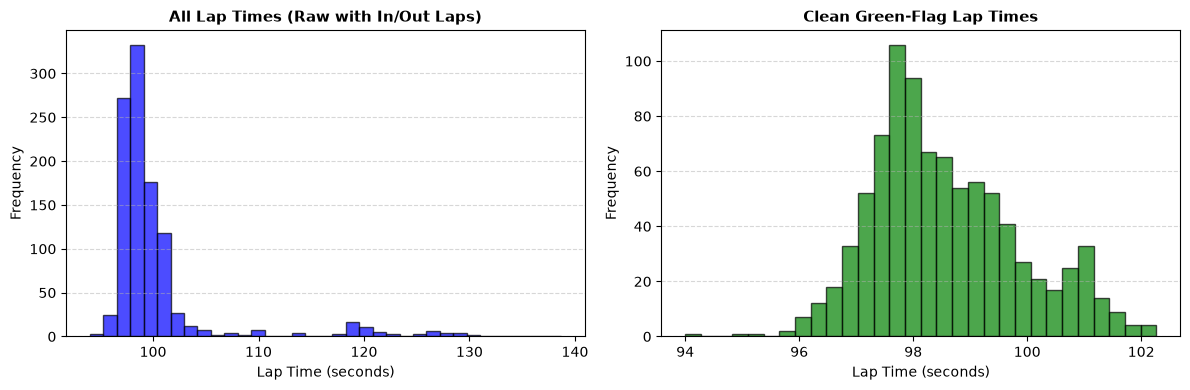

Clean Lap Times Summary:
count    889.000000
mean      98.558884
std        1.297615
min       93.996000
25%       97.651000
50%       98.315000
75%       99.356000
max      102.267000
Name: LapTimeSeconds, dtype: float64


In [4]:
# Lap Times Distribution Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(df_laps['LapTimeSeconds'].dropna(), bins=35, color='blue', edgecolor='black', alpha=0.7)
ax1.set_title('All Lap Times (Raw with In/Out Laps)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Lap Time (seconds)')
ax1.set_ylabel('Frequency')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

ax2.hist(clean_laps['LapTimeSeconds'], bins=30, color='green', edgecolor='black', alpha=0.7)
ax2.set_title('Clean Green-Flag Lap Times', fontsize=11, fontweight='bold')
ax2.set_xlabel('Lap Time (seconds)')
ax2.set_ylabel('Frequency')
ax2.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print('Clean Lap Times Summary:')
print(clean_laps['LapTimeSeconds'].describe())

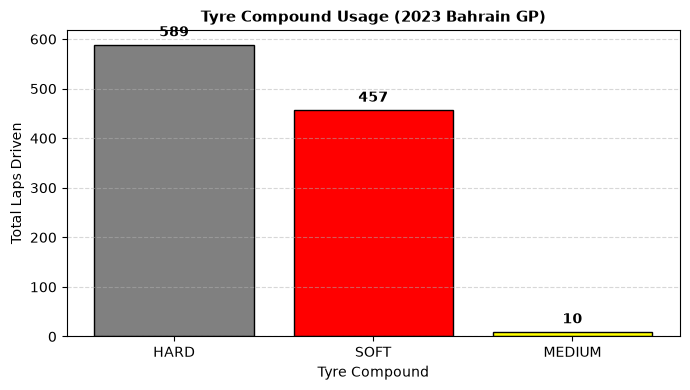

Compound Counts:
Compound
HARD      589
SOFT      457
MEDIUM     10
Name: count, dtype: int64


In [5]:
#Tyre Compound Distribution Plot
compound_counts = df_laps['Compound'].value_counts()
colors = {'HARD': 'gray', 'SOFT': 'red', 'MEDIUM': 'yellow'}
bar_colors = [colors.get(c, '#cccccc') for c in compound_counts.index]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(compound_counts.index, compound_counts.values, color=bar_colors, edgecolor='black')
ax.set_title('Tyre Compound Usage (2023 Bahrain GP)', fontsize=11, fontweight='bold')
ax.set_xlabel('Tyre Compound')
ax.set_ylabel('Total Laps Driven')
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 10, int(yval), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print('Compound Counts:')
print(compound_counts)

## DHL pit-stop data exploration

DHL's award page loads its tables in the browser, and we have not inspected its endpoint. This section uses the GitHub mirror `Jordan-Soria/PitStops`, which is scraped from that page and is what the `f1pits` R package reads. It checks format, fields, coverage and data issues only. **No performance conclusions.**

The raw sample files are in `sample_data/` and are kept unchanged:
- `dhl_pitstops_2023_r01_bahrain.tsv`: one race (tab-separated, despite `.csv` in the mirror)
- `dhl_pitstop_champ_2023.tsv`: season award standings


In [ ]:
def read_dhl(path_or_url):
    """Read a DHL mirror file: tab-separated, CRLF, trailing spaces in headers/values."""
    df = pd.read_csv(path_or_url, sep='\t', dtype=str, on_bad_lines='warn')
    df.columns = df.columns.str.strip()
    df = df.apply(lambda s: s.str.strip())
    for col in ['Pos.', 'Time (sec)', 'Lap', 'Points']:
        if col in df:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    return df

dhl_race = read_dhl(Path('sample_data') / 'dhl_pitstops_2023_r01_bahrain.tsv')
dhl_champ = read_dhl(Path('sample_data') / 'dhl_pitstop_champ_2023.tsv')

for name, df in {'DHL race (2023 R1)': dhl_race, 'DHL standings (2023)': dhl_champ}.items():
    print(f'\n--- {name}: {df.shape} ---')
    print(df.dtypes.to_string())
    print('Nulls:', df.isna().sum().to_dict())
print('\nFirst rows of the race file:')
print(dhl_race.head())
print('\nPos. is 1..n:', dhl_race['Pos.'].tolist() == list(range(1, len(dhl_race) + 1)))
print('Points values:', sorted(dhl_race['Points'].astype(int).unique().tolist()))
raw_time = pd.read_csv(Path('sample_data') / 'dhl_pitstops_2023_r01_bahrain.tsv', sep='\t', dtype=str).iloc[:, 3].str.strip()
print('Decimals in raw Time (sec):', raw_time.str.split('.').str[1].str.len().value_counts().to_dict())
print('Rows (stops) vs FastF1 in-laps for the same race:', len(dhl_race), 'vs', df_laps['PitInTime'].notna().sum())


### Coverage across seasons

This lists each season's folder through the GitHub API (about 10 requests, well under the 60/hour limit without a token) and caches the raw files in `dhl_cache/`, so later runs don't download them again. It reports coverage and format problems only.


In [ ]:
import re, requests

MIRROR_API = 'https://api.github.com/repos/Jordan-Soria/PitStops/contents'
MIRROR_RAW = 'https://raw.githubusercontent.com/Jordan-Soria/PitStops/main'
CACHE = Path('dhl_cache')

def cached(rel):
    path = CACHE / rel
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        r = requests.get(f'{MIRROR_RAW}/{rel}', timeout=30)
        r.raise_for_status()
        path.write_bytes(r.content)
    return path

frames, problems, file_rows = [], [], []
for year in range(2018, 2027):
    listing = requests.get(f'{MIRROR_API}/{year}', timeout=30).json()
    if not isinstance(listing, list):          # e.g. GitHub rate-limit message
        raise RuntimeError(f'{year}: {listing.get("message")}')
    for f in [x['name'] for x in listing if x['name'].endswith('.csv')]:
        rnd = int(re.match(r'\d+', f).group())
        try:
            df = pd.read_csv(cached(f'{year}/{f}'), sep='\t', dtype=str)   # strict parse to catch bad rows
        except pd.errors.ParserError as e:
            problems.append((year, f, str(e).splitlines()[-1]))
            df = pd.read_csv(cached(f'{year}/{f}'), sep='\t', dtype=str, on_bad_lines='skip')
        df.columns = df.columns.str.strip()
        file_rows.append((year, f, len(df)))
        frames.append(df.apply(lambda s: s.str.strip()).assign(year=year, round=rnd, file=f))

dhl_all = pd.concat(frames, ignore_index=True)
for col in ['Pos.', 'Time (sec)', 'Lap', 'Points']:
    dhl_all[col] = pd.to_numeric(dhl_all[col], errors='coerce')

file_rows = pd.DataFrame(file_rows, columns=['year', 'file', 'rows'])
coverage = (file_rows.groupby('year').agg(race_files=('file', 'size'), stops=('rows', 'sum'),
                                          min_rows=('rows', 'min'), max_rows=('rows', 'max'))
            .join(dhl_all.groupby('year').agg(missing_lap=('Lap', lambda s: s.isna().sum()),
                                              missing_points=('Points', lambda s: s.isna().sum()))))
print(coverage.to_string())
print('\nHeader-only files:', file_rows[file_rows.rows == 0][['year', 'file']].values.tolist())
print('\nStrict-parse problems:', problems)
print('Same driver + lap listed twice:',
      dhl_all[dhl_all.Lap.notna()].duplicated(['year', 'file', 'Driver', 'Lap'], keep=False).sum(), 'rows')
print('\nTeam names seen:', sorted(dhl_all['Team'].unique()))


## Next questions

- How does qualifying position relate to finishing position with a full season of data?
- Which drivers gain or lose the most places from qualifying or the grid?
- Can we add pit-stop, circuit, weather, and lap data for the broader project questions?
